In [ ]:

# Cell 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("AI Financial Analytics System Initialized!")


AI Financial Analytics System Initialized!


In [ ]:

# Cell 2: Generate Synthetic Financial Data

np.random.seed(42)

dates = pd.date_range(
    start="2022-01-01",
    periods=60,
    freq="MS"
)

revenue = (
    50000
    + np.arange(60) * 1500
    + np.random.normal(0, 5000, 60)
)

expenses = (
    revenue * np.random.uniform(0.55, 0.80, 60)
)

financial_data = pd.DataFrame({
    "Date": dates,
    "Revenue": revenue.round(2),
    "Expenses": expenses.round(2)
})

financial_data["Profit"] = (
    financial_data["Revenue"] - financial_data["Expenses"]
)

financial_data["Profit_Margin"] = (
    financial_data["Profit"] /
    financial_data["Revenue"] * 100
)

financial_data["Growth"] = (
    financial_data["Revenue"].pct_change() * 100
)

display(financial_data.head())


,Date,Revenue,Expenses,Profit,Profit_Margin,Growth
0,2022-01-01,52483.57,33207.64,19275.93,36.727551,NaN
1,2022-02-01,50808.68,28752.10,22056.58,43.411047,-3.191265
2,2022-03-01,56238.44,35303.43,20935.01,37.225446,10.686678
3,2022-04-01,62115.15,39213.03,22902.12,36.870425,10.449632
4,2022-05-01,54829.23,40157.02,14672.21,26.759832,-11.729699


In [ ]:

# Cell 3: Basic Financial Statistics

print("Dataset Shape:", financial_data.shape)

print("\nTotal Revenue:",
      round(financial_data["Revenue"].sum(), 2))

print("Total Expenses:",
      round(financial_data["Expenses"].sum(), 2))

print("Total Profit:",
      round(financial_data["Profit"].sum(), 2))

print("Average Profit Margin:",
      round(financial_data["Profit_Margin"].mean(), 2), "%")

display(financial_data.describe())


Dataset Shape: (60, 6)

Total Revenue: 5608603.59
Total Expenses: 3789987.41
Total Profit: 1818616.18
Average Profit Margin: 32.66 %


,Date,Revenue,Expenses,Profit,Profit_Margin,Growth
count,60,60.000000,60.000000,60.000000,60.000000,59.000000
mean,2024-06-16 01:36:00,93476.726500,63166.456833,30310.269667,32.661152,1.993542
min,2022-01-01 00:00:00,50808.680000,28752.100000,14672.210000,20.705445,-13.403028
25%,2023-03-24 06:00:00,69141.317500,46242.592500,21741.440000,25.916730,-3.812395
50%,2024-06-16 00:00:00,92210.010000,64565.190000,27240.820000,32.924863,2.454794
75%,2025-09-08 12:00:00,113744.442500,79156.880000,38807.222500,38.721008,7.707915
max,2026-12-01 00:00:00,143377.730000,109623.320000,55494.990000,44.826195,22.242579
std,NaN,26525.785872,19964.889459,10731.729805,7.295418,7.592957


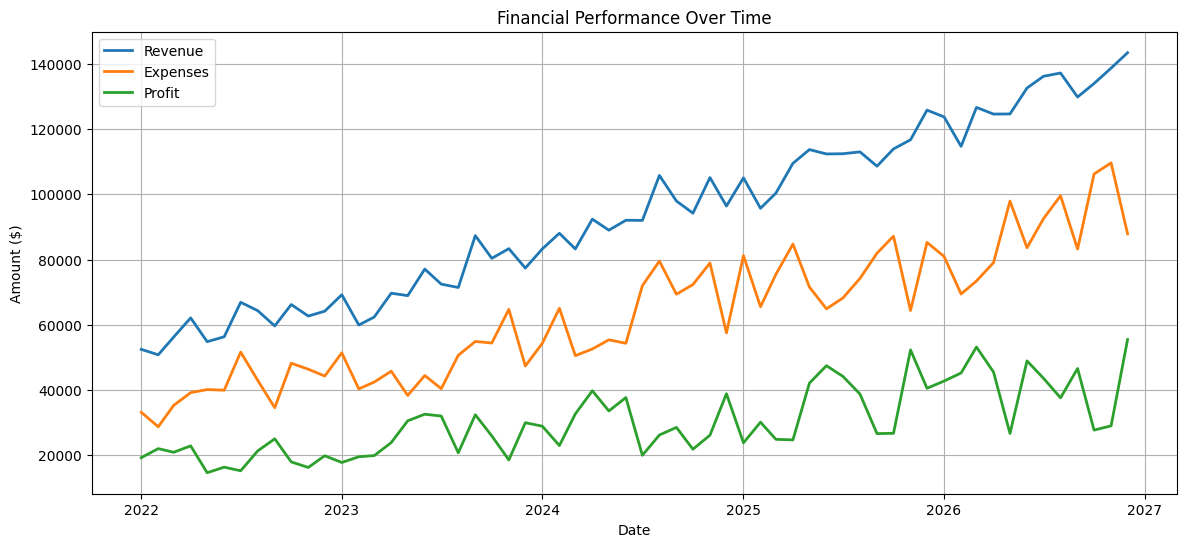

In [ ]:

# Cell 4: Revenue, Expenses & Profit Trends

plt.figure(figsize=(14, 6))

plt.plot(
    financial_data["Date"],
    financial_data["Revenue"],
    label="Revenue",
    linewidth=2
)

plt.plot(
    financial_data["Date"],
    financial_data["Expenses"],
    label="Expenses",
    linewidth=2
)

plt.plot(
    financial_data["Date"],
    financial_data["Profit"],
    label="Profit",
    linewidth=2
)

plt.title("Financial Performance Over Time")
plt.xlabel("Date")
plt.ylabel("Amount ($)")
plt.legend()
plt.grid(True)
plt.show()


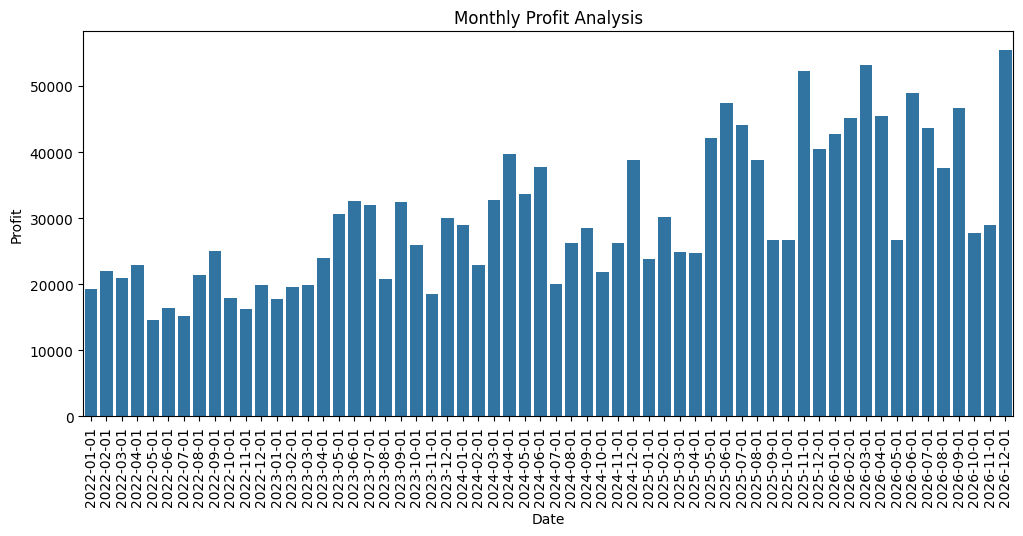

In [ ]:

# Cell 5: Profit Analysis

plt.figure(figsize=(12, 5))

sns.barplot(
    data=financial_data,
    x="Date",
    y="Profit"
)

plt.title("Monthly Profit Analysis")
plt.xticks(rotation=90)
plt.show()


In [ ]:

# Cell 6: Feature Engineering

ml_data = financial_data.copy()

# Previous month's revenue
ml_data["Revenue_Lag1"] = ml_data["Revenue"].shift(1)

# Previous 3 months average
ml_data["Revenue_MA3"] = (
    ml_data["Revenue"].shift(1).rolling(3).mean()
)

# Previous month's expenses
ml_data["Expenses_Lag1"] = ml_data["Expenses"].shift(1)

ml_data["Month"] = ml_data["Date"].dt.month
ml_data["Year"] = ml_data["Date"].dt.year

ml_data.dropna(inplace=True)

features = [
    "Revenue_Lag1",
    "Revenue_MA3",
    "Expenses_Lag1",
    "Month",
    "Year"
]

X = ml_data[features]
y = ml_data["Revenue"]


In [ ]:

# Cell 7: Train-Test Split

split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train Random Forest
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [ ]:

# Cell 8: Model Evaluation

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Model Performance")
print("-------------------------")
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")


Model Performance
-------------------------
MAE:  $13,724.52
RMSE: $15,143.38
R² Score: -2.8967


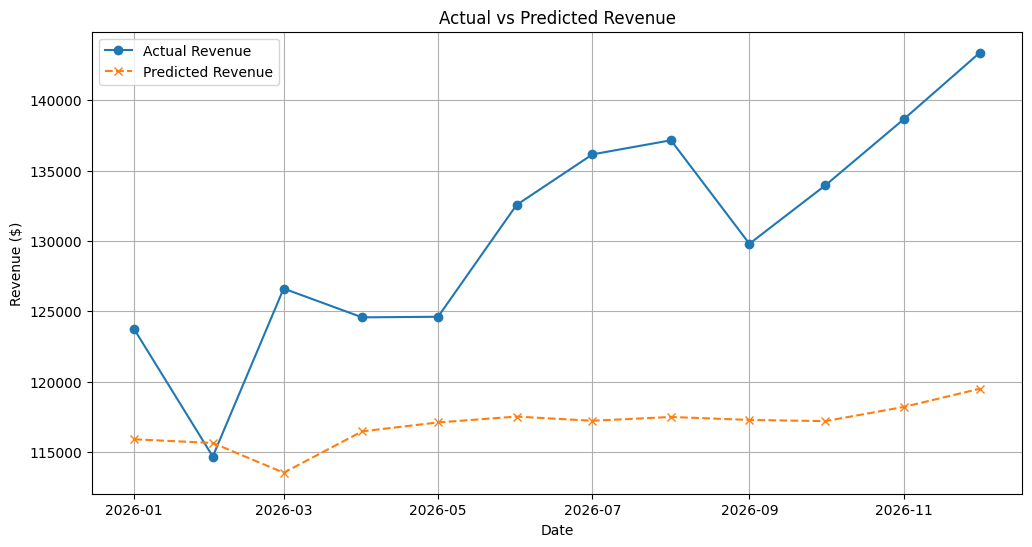

In [ ]:

# Cell 9: Prediction Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    ml_data["Date"].iloc[split_index:],
    y_test,
    label="Actual Revenue",
    marker="o"
)

plt.plot(
    ml_data["Date"].iloc[split_index:],
    predictions,
    label="Predicted Revenue",
    marker="x",
    linestyle="--"
)

plt.title("Actual vs Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue ($)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# Cell 10: Forecast Next Month Revenue

latest = ml_data.iloc[-1]

next_month = latest["Date"] + pd.DateOffset(months=1)

next_features = pd.DataFrame([{
    "Revenue_Lag1": latest["Revenue"],
    "Revenue_MA3": ml_data["Revenue"].tail(3).mean(),
    "Expenses_Lag1": latest["Expenses"],
    "Month": next_month.month,
    "Year": next_month.year
}])[features]

forecast = model.predict(next_features)[0]

print("Next Month:", next_month.strftime("%B %Y"))
print(f"Predicted Revenue: ${forecast:,.2f}")


Next Month: January 2027
Predicted Revenue: $116,078.24


In [ ]:

# Cell 11: AI-Generated Financial Insights

total_revenue = financial_data["Revenue"].sum()
total_expenses = financial_data["Expenses"].sum()
total_profit = financial_data["Profit"].sum()

profit_margin = (
    total_profit / total_revenue
) * 100

print("===== FINANCIAL ANALYTICS REPORT =====\n")

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Expenses: ${total_expenses:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")

if profit_margin > 25:
    print("\nInsight: Strong profitability.")
elif profit_margin > 10:
    print("\nInsight: Moderate profitability.")
else:
    print("\nInsight: Low profitability. Review expenses.")

growth = financial_data["Revenue"].pct_change().mean() * 100

if growth > 0:
    print("Insight: Revenue shows a positive average trend.")
else:
    print("Insight: Revenue shows a negative average trend.")


===== FINANCIAL ANALYTICS REPORT =====

Total Revenue: $5,608,603.59
Total Expenses: $3,789,987.41
Total Profit: $1,818,616.18
Overall Profit Margin: 32.43%

Insight: Strong profitability.
Insight: Revenue shows a positive average trend.


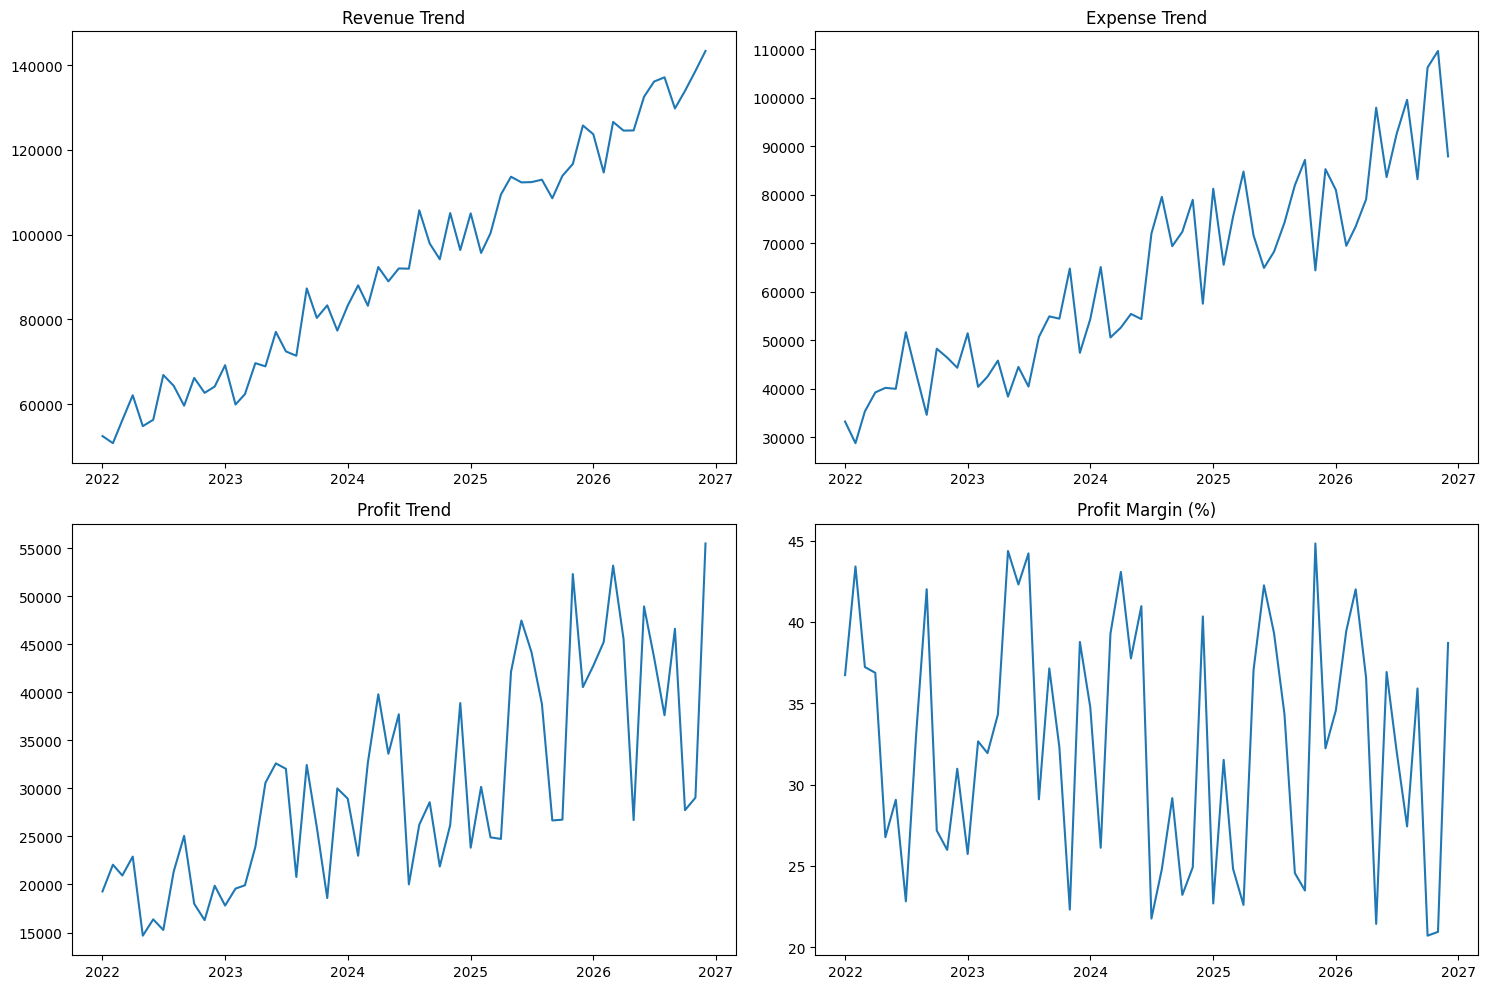

In [ ]:

# Cell 12: KPI Dashboard

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Revenue
axes[0, 0].plot(
    financial_data["Date"],
    financial_data["Revenue"]
)
axes[0, 0].set_title("Revenue Trend")

# Expenses
axes[0, 1].plot(
    financial_data["Date"],
    financial_data["Expenses"]
)
axes[0, 1].set_title("Expense Trend")

# Profit
axes[1, 0].plot(
    financial_data["Date"],
    financial_data["Profit"]
)
axes[1, 0].set_title("Profit Trend")

# Profit margin
axes[1, 1].plot(
    financial_data["Date"],
    financial_data["Profit_Margin"]
)
axes[1, 1].set_title("Profit Margin (%)")

plt.tight_layout()
plt.show()


In [ ]:

# Cell 13: Export Financial Analytics Results

financial_data.to_csv(
    "Financial_Analytics_Report.csv",
    index=False
)

forecast_results = pd.DataFrame({
    "Date": ml_data["Date"].iloc[split_index:],
    "Actual_Revenue": y_test.values,
    "Predicted_Revenue": predictions
})

forecast_results.to_csv(
    "Revenue_Predictions.csv",
    index=False
)

print("Reports exported successfully!")


Reports exported successfully!


In [ ]:

# Cell 14: Download Reports

from google.colab import files

files.download("Financial_Analytics_Report.csv")
files.download("Revenue_Predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>